## Exercise 7 - Text Clustering

**Disusun Oleh :**

*Nayla Salsabila Az Zahra - 25031554268*

# **TEXT CLUSTERING**

**Instruksi Exercise 7:** *Try applying all clustering methods on the text you have feature engineering from the previous exercise and analyze the given results.*

Notebook ini melanjutkan **Exercise 6 (Text Similarity)**: data dan feature engineering yang dipakai persis sama, yaitu judul berita **CNN Indonesia - Kategori Ekonomi** (https://www.cnnindonesia.com/ekonomi) yang sudah dibersihkan (preprocessing) lalu diubah menjadi representasi **Bag-of-Words (BoW)** dan **TF-IDF**. Pada notebook ini representasi tersebut dipakai untuk mencoba **semua metode clustering** yang diajarkan di kelas, yaitu:

1. **K-Means**
2. **Hierarchical / Agglomerative Clustering (Ward linkage)**

Kedua metode diterapkan pada representasi TF-IDF (representasi utama) maupun BoW (sebagai pembanding), kemudian dibandingkan menggunakan **Silhouette Score**, **Adjusted Rand Index**, serta dianalisis kata-kata penciri tiap cluster.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)

## 1. Memuat Data (lanjutan dari Exercise 6)

Data diambil dengan urutan berikut supaya notebook ini tetap bisa dijalankan ulang (*reproducible*) walau tanpa koneksi internet:

1. Jika file `cnn_ekonomi_preprocessed.csv` hasil Exercise 6 sudah ada di folder yang sama, file itu dipakai lagi (ini kondisi normal kalau Exercise 6 dan 7 dijalankan berurutan di Google Colab/Jupyter yang sama).
2. Jika file itu tidak ada, notebook mencoba **scraping baru** dari CNN Indonesia (fungsi scraping identik dengan Exercise 6).
3. Jika scraping juga tidak berhasil (misalnya tidak ada koneksi internet saat notebook ini dijalankan ulang), dipakai **data cadangan**: judul-judul berita yang sama persis dengan yang dipakai pada Exercise 6.

In [2]:
# Daftar stopword Bahasa Indonesia (dipakai manual karena corpus NLTK
# "indonesian" membutuhkan koneksi internet untuk diunduh; kalau internet
# tersedia, boleh juga pakai: nltk.download("stopwords"); stopwords.words("indonesian"))
STOP_ID = set("""
yang untuk dengan pada dan di ke dari ini itu juga akan atau karena oleh
sebagai adalah tidak bisa dapat para ada saat sudah belum masih dalam atas
bawah antara setelah sebelum hingga sampai agar supaya jika kalau maka
namun tetapi serta bahwa yaitu yakni lebih paling sangat sekali saja pun
lah kah nya mu ku kita kami mereka dia ia saya aku kamu anda per soal usai
jadi kata ungkap ujar sebut terkait hari ini besok kemarin pagi siang sore
malam telah tengah kembali lagi kini tersebut masing masing sejumlah
beberapa seperti terhadap guna demi tanpa tak
""".split())

# Fungsi preprocessing yang sama seperti pada Exercise 6
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [3]:
import os

def scrape_page(url):
    import requests
    from bs4 import BeautifulSoup
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers, timeout=20)
    if response.status_code != 200:
        return []
    soup = BeautifulSoup(response.text, "html.parser")
    hasil = []
    for a in soup.select("a[href*='/ekonomi/20']"):
        h = a.find(["h2", "h3"])
        title = h.get_text(" ", strip=True) if h else (a.get("dtr-ttl") or "")
        if len(title) > 15:
            hasil.append(title)
    return hasil

# Data cadangan: judul-judul berita CNN Indonesia Ekonomi yang SAMA dengan
# yang dipakai pada Exercise 6 (Text Similarity). Dipakai sebagai fallback
# agar notebook ini tetap bisa dijalankan ulang (reproducible) walau tanpa
# koneksi internet / situs sedang tidak bisa diakses.
FALLBACK_TITLES = [
    "Wamenkeu Pamer Proyek Weda Bay dan Pabrik BYD Jadi Bukti Hilirisasi",
    "Said Iqbal Minta PT Pos Perjelas Status Hubungan Kerja Para Pekerja",
    "VIDEO: Berkah Karbon dari Belantara Jambi",
    "Bos Pertamina Buka Suara soal Antrean Panjang BBM di SPBU Bali",
    "Buruh Desak Pemerintah Batasi Outsourcing, Hapus Pesangon 0,5 Kali",
    "Ada Gangguan Listrik di Batam, Bahlil Bakal Rapat dengan PLN",
    "Amran Blak-blakan 82 Persen Kebutuhan Susu RI Masih Dipenuhi Impor",
    "Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini",
    "BGN Bongkar Modus Penipuan Janjikan Percepatan Aktivasi Dapur MBG",
    "BGN Tutup Permanen 2 Dapur MBG di Jateng",
    "BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026",
    "BRI Perkuat Ekonomi Lokal dan Sport Tourism di MotoGP Mandalika 2026",
    "Bahlil Dorong UMKM, Koperasi dan Pengusaha Lokal Masuk Bisnis Tambang",
    "Buruh Siapkan Aksi di 38 Provinsi Tuntut Upah Naik 9,5 Persen di 2027",
    "Harga Cabai Merah Naik di 314 Daerah, Tertinggi Rp193 Ribu per Kg",
    "Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini",
    "Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",
    "Harga Minyak Dunia Anjlok Usai Trump Klaim Rusia-Ukraina Sepakat Damai",
    "Harga Minyak Dunia Turun Usai Trump Izinkan Rusia Pasok Diesel Global",
    "IHSG Diperkirakan Ceria Awali Pekan Ini",
    "IHSG Diproyeksi Makin Turun Hari Ini",
    "IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini",
    "IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",
    "InJourney Perkuat Sport Tourism Mandalika Usai Rekor Baru Penonton",
    "Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini",
    "Jelang COP31 Turki, Indonesia Incar Investasi Hijau dan Pasar Karbon",
    "Kemenhub Pantau Dampak Serangan di Riyadh Saudi ke Penerbangan RI",
    "Koster soal BBM di Bali: Pasokan Tersedia di Depo",
    "PT Tiran Nusantara Grup dan Conch Sepakati Investasi Rp10 Triliun",
    "Pemerintah Evaluasi Penanganan Karhutla di Kalimantan Sore Ini",
    "Penerbangan Transit Dubai dari RI ke Riyadh dan Jeddah Dibatalkan",
    "Pertamina Bongkar Penyebab Antrean Panjang Pembelian BBM di Jember",
    "Pertamina Patra Niaga Antisipasi Lonjakan Konsumsi BBM di Bondowoso",
    "Pertamina Patra Niaga Kebut Pemulihan Pasokan BBM Bali 24 Jam",
    "Pertamina Tambah Pasokan BBM Pertalite-Pertamax 26.200 KL di Bali",
    "Potensi Benih Lobster 465,8 Juta Ekor, Pemerintah Bentuk Satgas Khusus",
    "Prabowo Perintahkan Amran Berantas Mafia yang Mainkan Harga Pangan",
    "Robert E Hall dan Michael Woodford Jadi Peraih Nobel Ekonomi 2026",
    "Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi",
    "Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi",
    "Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore",
    "Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini",
    "Satgas P2BBL Diresmikan, Bergerak Lawan Penyelundupan Benih Lobster",
    "Selat Hormuz Sudah Terbuka, Kenapa Harga BBM Masih Mahal?",
    "Wamenko Dradjad Bantah Daya Beli Melemah",
]

def get_titles():
    """1) pakai cnn_ekonomi_preprocessed.csv dari Exercise 6 kalau ada,
       2) coba scraping baru,
       3) fallback ke data cadangan di atas."""
    if os.path.exists("cnn_ekonomi_preprocessed.csv"):
        print("Menemukan file dari Exercise 6, memuat ulang: cnn_ekonomi_preprocessed.csv")
        df_prev = pd.read_csv("cnn_ekonomi_preprocessed.csv")
        return df_prev["raw_title"].tolist(), "file Exercise 6 (cnn_ekonomi_preprocessed.csv)"

    print("Mencoba scraping judul berita baru dari CNN Indonesia...")
    titles = []
    try:
        titles += scrape_page("https://www.cnnindonesia.com/ekonomi")
        for page in range(1, 11):
            titles += scrape_page(f"https://www.cnnindonesia.com/ekonomi/indeks/5?page={page}")
    except Exception as e:
        print("Scraping tidak berhasil:", e)

    titles = list(dict.fromkeys(titles))
    if len(titles) >= 20:
        return titles, "scraping baru"

    print("Scraping tidak tersedia (mis. tidak ada koneksi internet) -> "
          "memakai data cadangan (judul yang sama seperti Exercise 6).")
    return FALLBACK_TITLES, "data cadangan (sama seperti Exercise 6)"

In [4]:
titles, sumber = get_titles()
print(f"Sumber data : {sumber}")

raw_df = pd.DataFrame({"raw_title": titles}).drop_duplicates().reset_index(drop=True)

df = raw_df.copy()
df["prepro"] = df["raw_title"].apply(preprocess_text)
df = df[df["prepro"].str.len() > 0]
df = df.drop_duplicates(subset=["prepro"]).reset_index(drop=True)
df.to_csv("cnn_ekonomi_preprocessed.csv", index=False)

df_pre = df["prepro"]
texts = df["raw_title"].tolist()

print(f"Jumlah dokumen (judul berita) setelah preprocessing : {len(df_pre)}")
print(df[["raw_title", "prepro"]].head(5).to_string(index=False))

Mencoba scraping judul berita baru dari CNN Indonesia...
Scraping tidak berhasil: HTTPSConnectionPool(host='www.cnnindonesia.com', port=443): Max retries exceeded with url: /ekonomi (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))
Scraping tidak tersedia (mis. tidak ada koneksi internet) -> memakai data cadangan (judul yang sama seperti Exercise 6).
Sumber data : data cadangan (sama seperti Exercise 6)
Jumlah dokumen (judul berita) setelah preprocessing : 45
                                                          raw_title                                                              prepro
Wamenkeu Pamer Proyek Weda Bay dan Pabrik BYD Jadi Bukti Hilirisasi wamenkeu pamer proyek weda bay dan pabrik byd jadi bukti hilirisasi
Said Iqbal Minta PT Pos Perjelas Status Hubungan Kerja Para Pekerja said iqbal minta pt pos perjelas status hubungan kerja para pekerja
                          VIDEO: Berkah Karbon dari Belantara Jambi      

## 2. Feature Engineering (sama seperti Exercise 6)

Membentuk representasi **Bag-of-Words (BoW)** dan **TF-IDF** dari judul berita yang sudah dipreprocessing, dengan parameter yang sama seperti Exercise 6 (`min_df=2`, `max_features=2000`), ditambah penghapusan stopword Bahasa Indonesia agar kata umum seperti "dan", "di", "yang" tidak mendominasi cluster.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Feature engineering sama seperti Exercise 6: Bag-of-Words dan TF-IDF
bow_vectorizer = CountVectorizer(min_df=2, max_features=2000, stop_words=list(STOP_ID))
X_bow = bow_vectorizer.fit_transform(df_pre)

tfidf_vectorizer = TfidfVectorizer(min_df=2, max_features=2000, sublinear_tf=True,
                                   stop_words=list(STOP_ID))
X_tfidf = tfidf_vectorizer.fit_transform(df_pre)

df_FE_bow = pd.DataFrame(X_bow.toarray(), columns=bow_vectorizer.get_feature_names_out())
df_FE_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

print("Ukuran matriks BoW    :", X_bow.shape)
print("Ukuran matriks TF-IDF :", X_tfidf.shape)

Ukuran matriks BoW    : (45, 62)
Ukuran matriks TF-IDF : (45, 62)


## 3. Clustering dengan K-Means

### 3.1 Menentukan jumlah cluster (k)

**Elbow Method** pada representasi TF-IDF:

k      : [2, 3, 4, 5, 6, 7]
inertia: [37.95, 35.38, 32.63, 30.22, 28.55, 26.08]


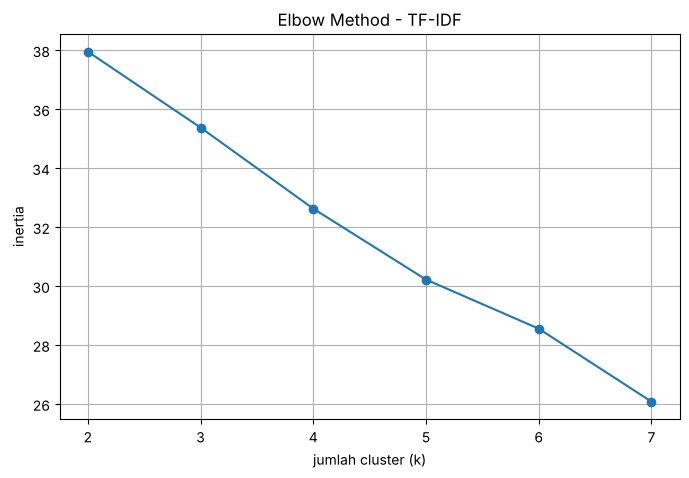

In [6]:
from sklearn.cluster import KMeans

k_range = range(2, 8)
inertia = []
for k in k_range:
    km_model = KMeans(n_clusters=k, random_state=10, n_init=10)
    km_model.fit(df_FE_tfidf)
    inertia.append(km_model.inertia_)

print("k      :", list(k_range))
print("inertia:", [round(x, 2) for x in inertia])

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertia, marker="o")
plt.xlabel("jumlah cluster (k)")
plt.ylabel("inertia")
plt.title("Elbow Method - TF-IDF")
plt.grid()
plt.show()

Selain elbow method, dicoba juga **Silhouette Score** untuk beberapa nilai k, agar pemilihan k tidak hanya mengandalkan kurva inertia:

In [7]:
from sklearn import metrics

print("Silhouette Score KMeans untuk beberapa nilai k (representasi TF-IDF):")
for k in range(2, 8):
    km_model = KMeans(n_clusters=k, random_state=10, n_init=10).fit(df_FE_tfidf)
    sil = metrics.silhouette_score(df_FE_tfidf, km_model.labels_, metric="euclidean")
    print(f"  k={k} -> silhouette={sil:.4f}")

Silhouette Score KMeans untuk beberapa nilai k (representasi TF-IDF):
  k=2 -> silhouette=0.0657
  k=3 -> silhouette=0.0947
  k=4 -> silhouette=0.1600
  k=5 -> silhouette=0.1609
  k=6 -> silhouette=0.1995
  k=7 -> silhouette=0.1980


Kurva elbow di atas melandai halus tanpa patahan yang tajam (wajar untuk korpus judul berita yang pendek dan jumlah dokumennya sedikit), sehingga elbow method sendiri kurang tegas menunjukkan nilai k yang "benar". Silhouette score justru terus naik seiring bertambahnya k - ini gejala umum pada data teks yang sangat sparse dengan jumlah dokumen kecil: semakin banyak cluster, semakin kecil & "murni" tiap cluster, sehingga nilai silhouette ikut naik meski clusternya sudah tidak informatif lagi (banyak cluster berisi 1-2 dokumen saja).

Karena itu, **k = 3** dipilih bukan semata dari angka tertinggi, melainkan karena jumlah ini memberi cluster yang paling mudah diinterpretasikan (lihat kata-kata penciri tiap cluster pada bagian berikut), sejalan dengan contoh pada materi kelas (Chapter 8) yang juga memilih k secara kualitatif, bukan otomatis.

In [8]:
n_clusters = 3

### 3.2 Fit K-Means (representasi TF-IDF)

In [9]:
kM = KMeans(n_clusters=n_clusters, random_state=10, n_init=10).fit(df_FE_tfidf)
df["Kmeans_tfidf"] = kM.labels_

print(df["Kmeans_tfidf"].value_counts().sort_index().rename("jumlah_dokumen"))

Kmeans_tfidf
0     8
1     6
2    31
Name: jumlah_dokumen, dtype: int64


**Silhouette Score**

In [10]:
sil_kmeans_tfidf = metrics.silhouette_score(df_FE_tfidf, kM.labels_, metric="euclidean")
print("Silhouette Score (KMeans, TF-IDF):", round(sil_kmeans_tfidf, 4))

Silhouette Score (KMeans, TF-IDF): 0.0947


**Word Cloud / Kata Penciri tiap Cluster**

Fungsi berikut mencoba menampilkan *word cloud* asli (paket `wordcloud`, seperti pada materi kelas); jika paket tersebut tidak terpasang di environment yang dipakai, ditampilkan diagram batang kata-kata dengan skor TF-IDF rata-rata tertinggi tiap cluster sebagai gantinya - secara substansi memberi informasi yang sama (kata paling mencirikan tiap cluster), hanya beda bentuk visualisasinya.

In [11]:
def top_words_per_cluster(df_FE, labels, top_n=8):
    """Kata-kata dengan rata-rata skor tertinggi pada tiap cluster.
    Dipakai sebagai pengganti/ pendamping word cloud supaya analisis
    tetap bisa dibaca meski library `wordcloud` tidak terpasang."""
    out = {}
    labels = np.asarray(labels)
    for c in sorted(set(labels)):
        mean_scores = df_FE[labels == c].mean(axis=0)
        top = mean_scores.sort_values(ascending=False).head(top_n)
        out[c] = list(zip(top.index, top.values.round(3)))
    return out

def plot_top_words(df_FE, labels, title_prefix, color="steelblue"):
    tw = top_words_per_cluster(df_FE, labels)
    labels = np.asarray(labels)
    n_c = len(tw)
    fig, axes = plt.subplots(1, n_c, figsize=(5 * n_c, 4))
    if n_c == 1:
        axes = [axes]
    for ax, (c, words) in zip(axes, tw.items()):
        w = [x[0] for x in words][::-1]
        s = [x[1] for x in words][::-1]
        ax.barh(w, s, color=color)
        ax.set_title(f"Cluster {c} ({title_prefix})\nn={(labels == c).sum()}")
    plt.tight_layout()
    plt.show()
    return tw

def show_wordcloud_or_topwords(df, df_FE, label_col, cluster_id, title_prefix, color="steelblue"):
    """Coba tampilkan word cloud asli (butuh paket `wordcloud`); kalau
    tidak terpasang, tampilkan daftar kata teratas sebagai gantinya."""
    try:
        from wordcloud import WordCloud
        text_cluster = ",".join(df.loc[df[label_col] == cluster_id, "prepro"])
        wc = WordCloud(background_color="white", max_words=5000, contour_width=3)
        wc.generate(text_cluster)
        plt.figure(figsize=(6, 4))
        plt.imshow(wc)
        plt.axis("off")
        plt.title(f"{title_prefix} - cluster {cluster_id}")
        plt.show()
    except ImportError:
        print("Paket `wordcloud` tidak terpasang, menampilkan daftar kata teratas sebagai gantinya.")
        labels = df[label_col].values
        mean_scores = df_FE[labels == cluster_id].mean(axis=0)
        top = mean_scores.sort_values(ascending=False).head(8)
        print(top)

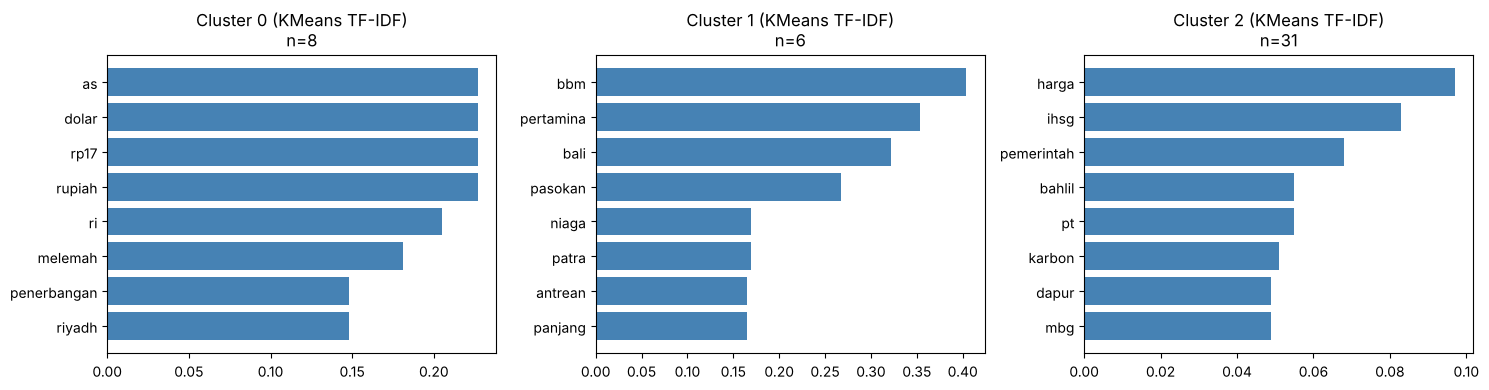

In [12]:
tw_kmeans_tfidf = plot_top_words(df_FE_tfidf, kM.labels_, "KMeans TF-IDF", color="steelblue")

### 3.3 Pembanding: K-Means pada representasi BoW

In [13]:
kM_bow = KMeans(n_clusters=n_clusters, random_state=10, n_init=10).fit(df_FE_bow)
df["Kmeans_bow"] = kM_bow.labels_
sil_kmeans_bow = metrics.silhouette_score(df_FE_bow, kM_bow.labels_, metric="euclidean")

print("Silhouette Score (KMeans, BoW):", round(sil_kmeans_bow, 4))
print(df["Kmeans_bow"].value_counts().sort_index().rename("jumlah_dokumen"))

Silhouette Score (KMeans, BoW): 0.1892
Kmeans_bow
0    35
1     6
2     4
Name: jumlah_dokumen, dtype: int64


## 4. Clustering dengan Hierarchical (Agglomerative)

### 4.1 Dendrogram (representasi TF-IDF, linkage ward)

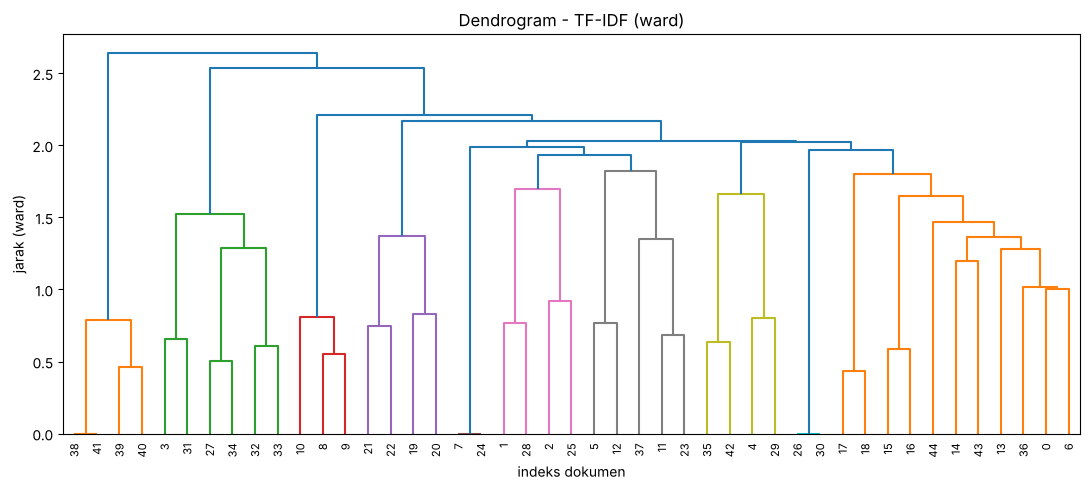

In [14]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_data = linkage(df_FE_tfidf, method="ward", metric="euclidean")

plt.figure(figsize=(11, 5))
dendrogram(linkage_data, labels=[str(i) for i in range(len(df_pre))])
plt.title("Dendrogram - TF-IDF (ward)")
plt.xlabel("indeks dokumen")
plt.ylabel("jarak (ward)")
plt.tight_layout()
plt.show()

### 4.2 Fit Agglomerative Clustering (representasi TF-IDF)

Referensi: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html

In [15]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_cluster = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
ward_labels = hierarchical_cluster.fit_predict(df_FE_tfidf)
df["Ward_tfidf"] = ward_labels

print(df["Ward_tfidf"].value_counts().sort_index().rename("jumlah_dokumen"))

Ward_tfidf
0    35
1     4
2     6
Name: jumlah_dokumen, dtype: int64


**Silhouette Score**

In [16]:
sil_hier_tfidf = metrics.silhouette_score(df_FE_tfidf, ward_labels, metric="euclidean")
print("Silhouette Score (Hierarchical/Ward, TF-IDF):", round(sil_hier_tfidf, 4))

Silhouette Score (Hierarchical/Ward, TF-IDF): 0.1199


**Kata Penciri tiap Cluster**

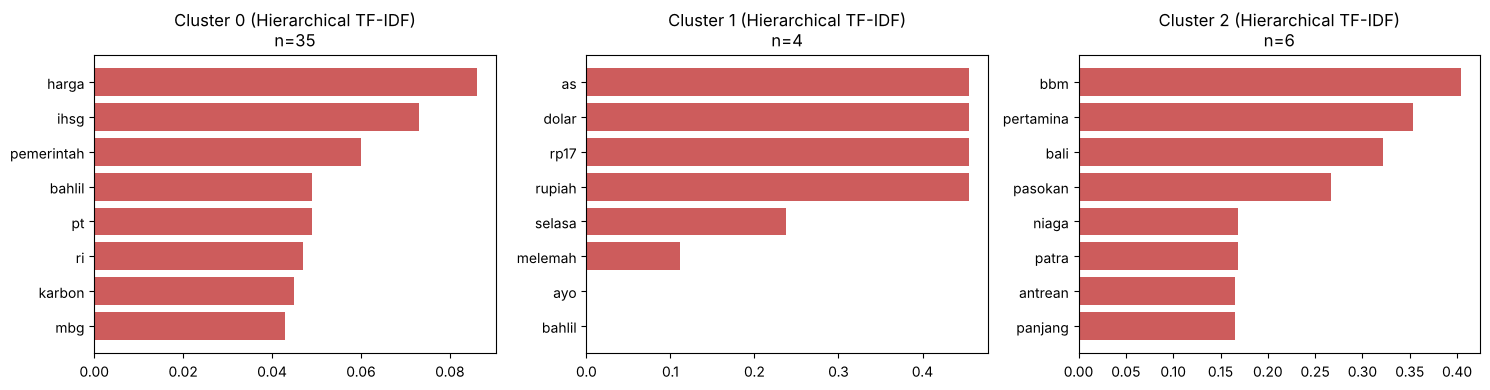

In [17]:
tw_hier_tfidf = plot_top_words(df_FE_tfidf, ward_labels, "Hierarchical TF-IDF", color="indianred")

### 4.3 Pembanding: Hierarchical pada representasi BoW

In [18]:
hier_bow = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
ward_bow_labels = hier_bow.fit_predict(df_FE_bow)
df["Ward_bow"] = ward_bow_labels

sil_hier_bow = metrics.silhouette_score(df_FE_bow, ward_bow_labels, metric="euclidean")
print("Silhouette Score (Hierarchical/Ward, BoW):", round(sil_hier_bow, 4))
print(df["Ward_bow"].value_counts().sort_index().rename("jumlah_dokumen"))

Silhouette Score (Hierarchical/Ward, BoW): 0.1892
Ward_bow
0    35
1     4
2     6
Name: jumlah_dokumen, dtype: int64


## 5. Kesesuaian Antar Metode (K-Means vs Hierarchical)

Untuk melihat seberapa mirip hasil kedua metode clustering, dihitung **Adjusted Rand Index (ARI)** (1 = identik, 0 = seperti acak) serta tabel silang (*crosstab*) label kedua metode.

In [19]:
from sklearn.metrics import adjusted_rand_score

ari_tfidf = adjusted_rand_score(df["Kmeans_tfidf"], df["Ward_tfidf"])
ari_bow = adjusted_rand_score(df["Kmeans_bow"], df["Ward_bow"])

print("Adjusted Rand Index KMeans vs Hierarchical (TF-IDF):", round(ari_tfidf, 4))
print("Crosstab KMeans vs Hierarchical (TF-IDF):")
print(pd.crosstab(df["Kmeans_tfidf"], df["Ward_tfidf"]))
print()
print("Adjusted Rand Index KMeans vs Hierarchical (BoW):", round(ari_bow, 4))
print("Crosstab KMeans vs Hierarchical (BoW):")
print(pd.crosstab(df["Kmeans_bow"], df["Ward_bow"]))

Adjusted Rand Index KMeans vs Hierarchical (TF-IDF): 0.7153
Crosstab KMeans vs Hierarchical (TF-IDF):
Ward_tfidf     0  1  2
Kmeans_tfidf          
0              4  4  0
1              0  0  6
2             31  0  0

Adjusted Rand Index KMeans vs Hierarchical (BoW): 1.0
Crosstab KMeans vs Hierarchical (BoW):
Ward_bow     0  1  2
Kmeans_bow          
0           35  0  0
1            0  0  6
2            0  4  0


## 6. Visualisasi 2D dengan PCA

Karena fitur TF-IDF berdimensi tinggi (puluhan kolom kata), hasil cluster diproyeksikan ke 2 dimensi dengan **PCA** agar bisa divisualisasikan.

Explained variance ratio (PC1, PC2): [0.0886 0.0805] - total: 0.1691


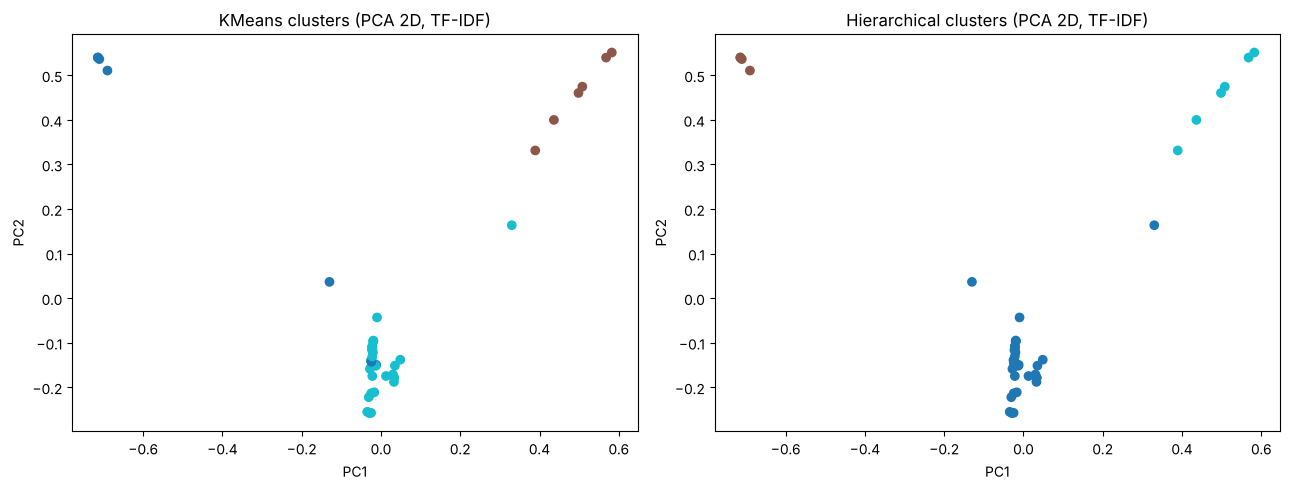

In [20]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(df_FE_tfidf)

print("Explained variance ratio (PC1, PC2):", pca.explained_variance_ratio_.round(4),
      "- total:", round(pca.explained_variance_ratio_.sum(), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(coords[:, 0], coords[:, 1], c=df["Kmeans_tfidf"], cmap="tab10")
axes[0].set_title("KMeans clusters (PCA 2D, TF-IDF)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

axes[1].scatter(coords[:, 0], coords[:, 1], c=df["Ward_tfidf"], cmap="tab10")
axes[1].set_title("Hierarchical clusters (PCA 2D, TF-IDF)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 7. Ringkasan Perbandingan Semua Metode

In [21]:
comparison = pd.DataFrame([
    {"metode": "KMeans",              "representasi": "TF-IDF", "silhouette": sil_kmeans_tfidf},
    {"metode": "KMeans",              "representasi": "BoW",    "silhouette": sil_kmeans_bow},
    {"metode": "Hierarchical (Ward)", "representasi": "TF-IDF", "silhouette": sil_hier_tfidf},
    {"metode": "Hierarchical (Ward)", "representasi": "BoW",    "silhouette": sil_hier_bow},
]).round(4)

print(comparison.to_string(index=False))

             metode representasi  silhouette
             KMeans       TF-IDF      0.0947
             KMeans          BoW      0.1892
Hierarchical (Ward)       TF-IDF      0.1199
Hierarchical (Ward)          BoW      0.1892


## 8. Menyimpan Hasil

In [22]:
df.to_csv("cnn_ekonomi_clustered.csv", index=False)
print(df.head(10).to_string())

                                                             raw_title                                                               prepro  Kmeans_tfidf  Kmeans_bow  Ward_tfidf  Ward_bow
0  Wamenkeu Pamer Proyek Weda Bay dan Pabrik BYD Jadi Bukti Hilirisasi  wamenkeu pamer proyek weda bay dan pabrik byd jadi bukti hilirisasi             2           0           0         0
1  Said Iqbal Minta PT Pos Perjelas Status Hubungan Kerja Para Pekerja  said iqbal minta pt pos perjelas status hubungan kerja para pekerja             2           0           0         0
2                            VIDEO: Berkah Karbon dari Belantara Jambi                             video berkah karbon dari belantara jambi             2           0           0         0
3       Bos Pertamina Buka Suara soal Antrean Panjang BBM di SPBU Bali       bos pertamina buka suara soal antrean panjang bbm di spbu bali             1           1           2         2
4   Buruh Desak Pemerintah Batasi Outsourcing, Hapus Pesango

## Analisis Hasil Clustering (Exercise 7)

*Hasil analisis setelah notebook dijalankan (data cadangan, 45 judul berita CNN Indonesia Ekonomi).*

**K-Means (TF-IDF).** Dengan k=3, K-Means menghasilkan satu cluster besar berisi 31 judul (topik campuran: IHSG, harga pangan/komoditas, kebijakan pemerintah, Bahlil, dapur MBG, dsb.) dan dua cluster kecil yang jauh lebih koheren: cluster berisi 8 judul dengan kata penciri "rupiah", "dolar", "as", "melemah" (semua tentang nilai tukar rupiah), dan cluster berisi 6 judul dengan kata penciri "bbm", "pertamina", "bali", "pasokan" (semua tentang pasokan BBM di Bali). Silhouette score-nya hanya 0,095 - rendah, namun ini sejalan dengan temuan di Exercise 6 bahwa judul berita sangat pendek sehingga sebagian besar pasangan dokumen tidak berbagi kata sama sekali (matriks TF-IDF sangat sparse), membuat jarak antar dokumen di luar dua topik khusus itu jadi kurang terpisah.

**Hierarchical/Ward (TF-IDF).** Hasilnya sangat mirip K-Means (ARI = 0,715): cluster BBM/Pertamina/Bali terbentuk persis sama (6 dokumen identik), sedangkan cluster rupiah yang semula 1 cluster di K-Means terpecah menjadi 2 sub-cluster yang lebih spesifik di hierarchical (4 dan 4 dokumen) - menunjukkan bahwa secara hierarkis topik "rupiah melemah/menguat" ini masih punya sub-tema (mis. berdasarkan hari pemberitaan). Silhouette-nya sedikit lebih tinggi (0,120) karena pemisahan yang lebih detail ini.

**Representasi BoW vs TF-IDF.** Menariknya, pada representasi BoW, K-Means dan Hierarchical menghasilkan partisi yang **identik** (ARI = 1,0, silhouette sama-sama 0,189), dan silhouette-nya lebih tinggi dibanding TF-IDF. Ini terjadi karena BoW hanya menghitung frekuensi kata mentah tanpa pembobotan, sehingga dokumen dengan kata unik yang sama persis (mis. "pertamina", "bbm", "bali") langsung membentuk gerombolan yang sangat rapat, membuat kedua algoritma clustering jatuh ke solusi yang sama. TF-IDF yang memberi bobot lebih halus (termasuk `sublinear_tf`) menghasilkan ruang fitur yang sedikit lebih "kabur" sehingga kedua metode bisa berbeda tipis.

**Keterbatasan.** PCA 2 komponen hanya menjelaskan sekitar 17% variansi total, jadi scatter plot 2D hanya menangkap sebagian kecil struktur data - dua cluster kecil (rupiah, BBM) tetap terlihat terpisah jauh dari kelompok utama, tapi pemisahan di dalam kelompok besar tidak sepenuhnya tergambar pada bidang 2D ini. Silhouette score yang relatif rendah untuk seluruh skema (0,09-0,19) adalah hal yang wajar untuk data berupa judul berita: jumlah dokumennya sedikit (45) dan tiap judul sangat pendek, sehingga sebagian besar dokumen tidak punya cukup kata yang sama untuk membentuk cluster yang benar-benar padat selain dua topik yang sangat spesifik (rupiah dan BBM).

**Kesimpulan.** Baik K-Means maupun Hierarchical berhasil menemukan dua topik niche yang jelas (rupiah/nilai tukar dan BBM/Pertamina Bali) secara konsisten di semua representasi, tetapi kesulitan memisahkan topik-topik umum ekonomi lainnya karena keterbatasan data (judul pendek, jumlah dokumen kecil). Untuk hasil cluster yang lebih tajam, data bisa diperkaya dengan isi berita lengkap (bukan hanya judul) atau menambah jumlah halaman yang di-scraping, sejalan dengan saran yang sudah dicatat pada analisis Exercise 6.